# 📊 Normal Distribution Analysis
### Claims Aggregated · Claims Engineered · Customer Engineered

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.facecolor": "#0f0f1a",
    "axes.facecolor": "#1a1a2e",
    "axes.edgecolor": "#444466",
    "axes.labelcolor": "#ccccff",
    "xtick.color": "#aaaacc",
    "ytick.color": "#aaaacc",
    "text.color": "#e0e0ff",
    "grid.color": "#2a2a4a",
    "grid.linestyle": "--",
    "grid.alpha": 0.4,
    "figure.dpi": 130,
    "font.family": "monospace",
})

PALETTES = {
    "claims_agg":    ["#7b2fff","#a855f7","#c084fc","#e879f9","#f0abfc",
                      "#5eead4","#22d3ee","#38bdf8","#60a5fa","#818cf8",
                      "#fb7185","#f472b6","#facc15","#34d399","#f97316"],
    "claims_eng":    ["#06b6d4","#0ea5e9","#3b82f6","#6366f1","#8b5cf6",
                      "#a855f7","#ec4899","#f43f5e","#10b981","#14b8a6",
                      "#f59e0b","#ef4444","#84cc16","#f97316","#e879f9"],
    "customer":      ["#22d3ee","#34d399","#a3e635","#fbbf24","#f87171",
                      "#c084fc","#fb923c","#38bdf8","#4ade80","#f472b6"],
}

print("✅ Libraries loaded")

✅ Libraries loaded


## 1 · Load Datasets

In [17]:
claims_agg = pd.read_csv("claims_aggregated.csv")
claims_eng = pd.read_csv("claims_engineered.csv")
customer    = pd.read_csv("customer_engineered.csv")

# ── Key columns only ──────────────────────────────────────────────
ca_num = ["annual_premium", "claim_to_premium_ratio",
          "avg_injury_claim", "avg_property_claim", "total_claim_amount"]

ce_num = ["policy_annual_premium", "incident_hour_of_the_day",
          "vehicle_age", "auto_year", "property_ratio"]

cu_num = ["tenure_years", "Premium", "Age",
          "premium_x_satisfaction", "age_x_claims"]

print(f"Claims Aggregated   → {len(ca_num)} key features")
print(f"Claims Engineered   → {len(ce_num)} key features")
print(f"Customer Engineered → {len(cu_num)} key features")

Claims Aggregated   → 5 key features
Claims Engineered   → 5 key features
Customer Engineered → 5 key features


## 2 · Helper — Normal Distribution Overlay

In [18]:
def plot_normal_grid(df, cols, palette, title, cols_per_row=3, height=3.8):
    """Plot histogram + KDE + fitted normal curve for each column."""
    # Drop columns with zero or near-zero variance (breaks KDE)
    valid_cols = [c for c in cols if df[c].dropna().std() > 1e-10 and df[c].dropna().nunique() > 2]
    skipped = set(cols) - set(valid_cols)
    if skipped:
        print(f"  ⚠️  Skipped (zero/near-zero variance): {skipped}")

    n = len(valid_cols)
    if n == 0:
        print("  ❌ No valid columns to plot.")
        return

    rows = (n + cols_per_row - 1) // cols_per_row
    fig, axes = plt.subplots(rows, cols_per_row,
                             figsize=(cols_per_row * 5.2, rows * height))
    axes = np.array(axes).flatten()

    for i, col in enumerate(valid_cols):
        ax = axes[i]
        data = df[col].dropna()
        color = palette[i % len(palette)]

        # Histogram (normalised to density)
        ax.hist(data, bins=35, density=True,
                color=color, alpha=0.35, edgecolor="none")

        # KDE curve — guard against singular covariance
        try:
            kde = stats.gaussian_kde(data)
            xs  = np.linspace(data.min(), data.max(), 300)
            ax.plot(xs, kde(xs), color=color, lw=2, label="KDE")
        except Exception:
            xs = np.linspace(data.min(), data.max(), 300)

        # Fitted normal curve
        mu, sigma = stats.norm.fit(data)
        if sigma > 0:
            ys = stats.norm.pdf(xs, mu, sigma)
            ax.plot(xs, ys, color="#ffffff", lw=1.5, linestyle="--", alpha=0.75, label="Normal fit")

        # Mean & ±1σ lines
        ax.axvline(mu, color="#facc15", lw=1.2, alpha=0.85)
        ax.axvspan(mu - sigma, mu + sigma, alpha=0.07, color="#facc15")

        # Shapiro-Wilk p-value (sample ≤ 5000)
        sample = data if len(data) <= 5000 else data.sample(5000, random_state=42)
        try:
            _, p = stats.shapiro(sample)
            normal_tag = "≈ Normal" if p > 0.05 else f"p={p:.2e}"
        except Exception:
            normal_tag = "n/a"

        ax.set_title(f"{col}\nμ={mu:.2f}  σ={sigma:.2f}  {normal_tag}",
                     fontsize=7.5, pad=4, color="#e0e0ff")
        ax.tick_params(labelsize=7)
        ax.grid(True, alpha=0.25)
        ax.legend(fontsize=6, loc="upper right",
                  facecolor="#1a1a2e", edgecolor="#444466")

    # Hide empty subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.01, color="#e0e0ff")
    plt.tight_layout()
    plt.show()
    print(f"  → {n} distributions plotted\n")

print("✅ Helper defined")

✅ Helper defined


## 3 · Claims Aggregated — Normal Distributions

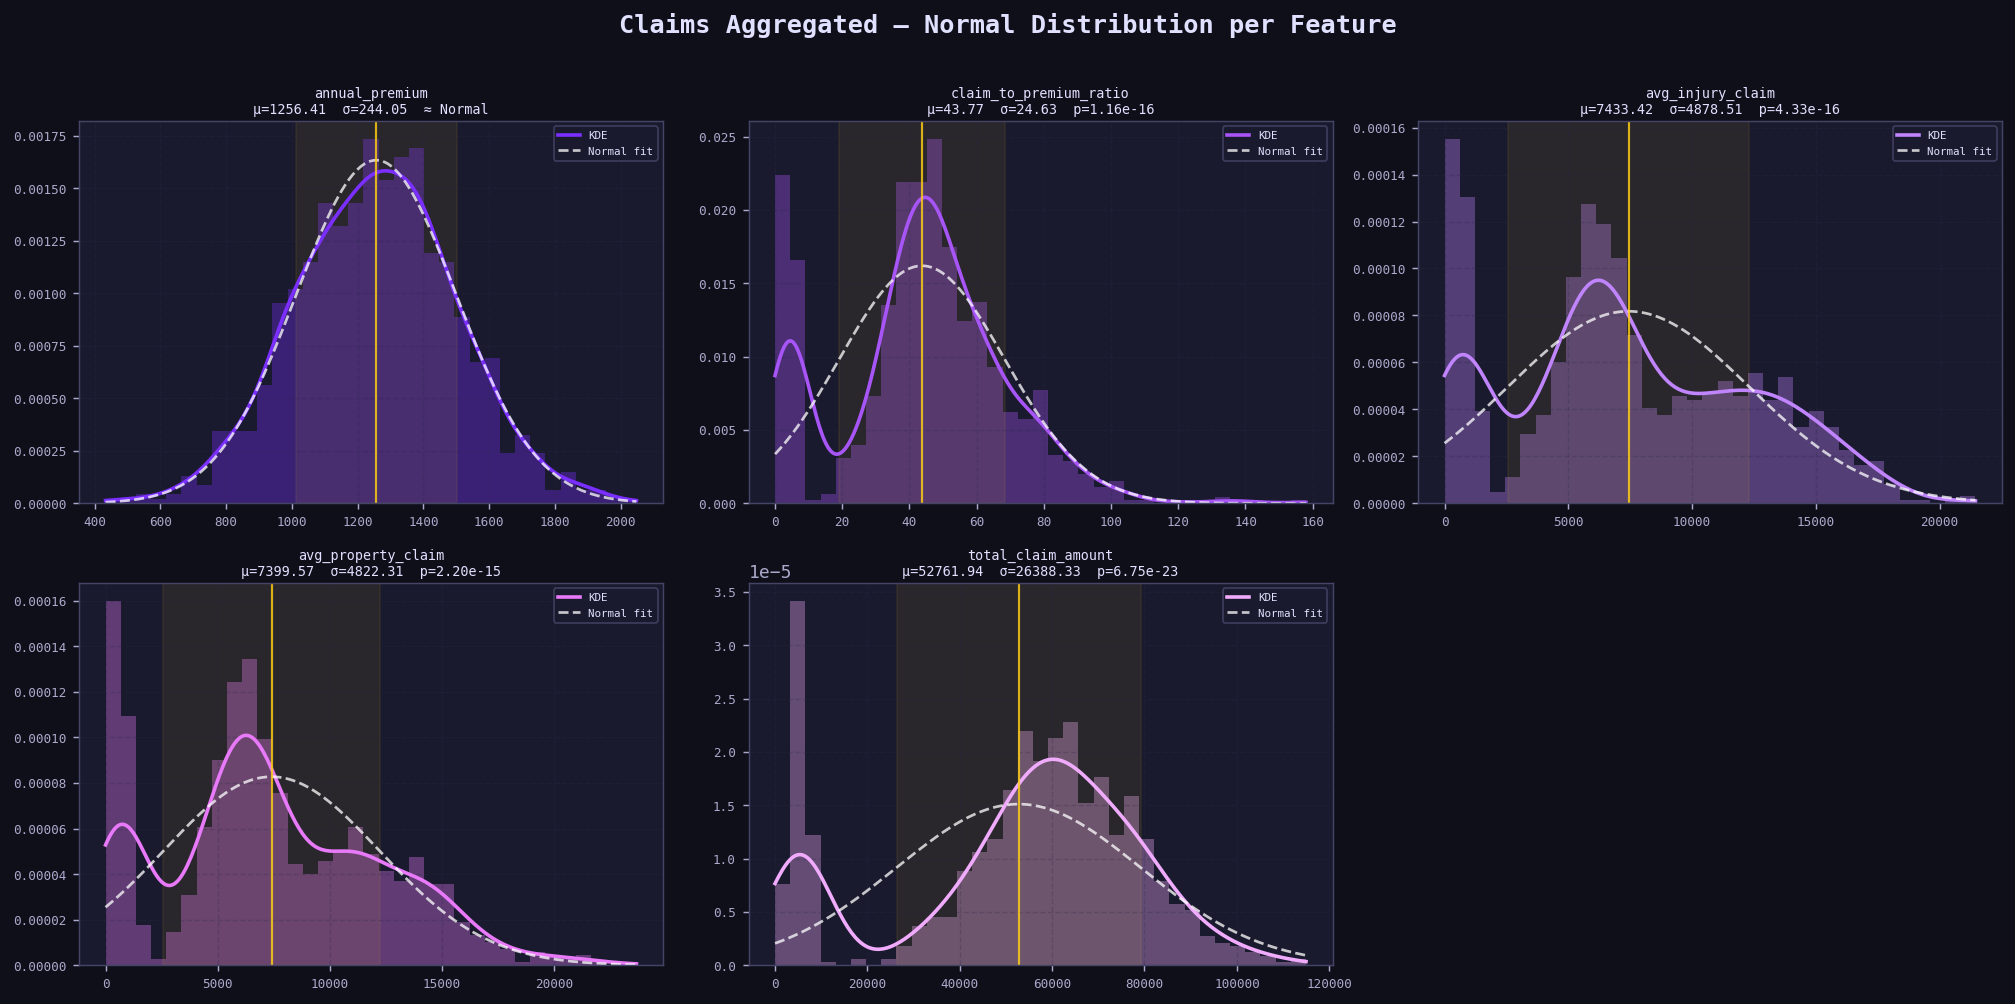

  → 5 distributions plotted



In [19]:
plot_normal_grid(
    claims_agg, ca_num,
    palette   = PALETTES["claims_agg"],
    title     = "Claims Aggregated — Normal Distribution per Feature",
    cols_per_row = 3,
)

## 4 · Claims Engineered — Normal Distributions

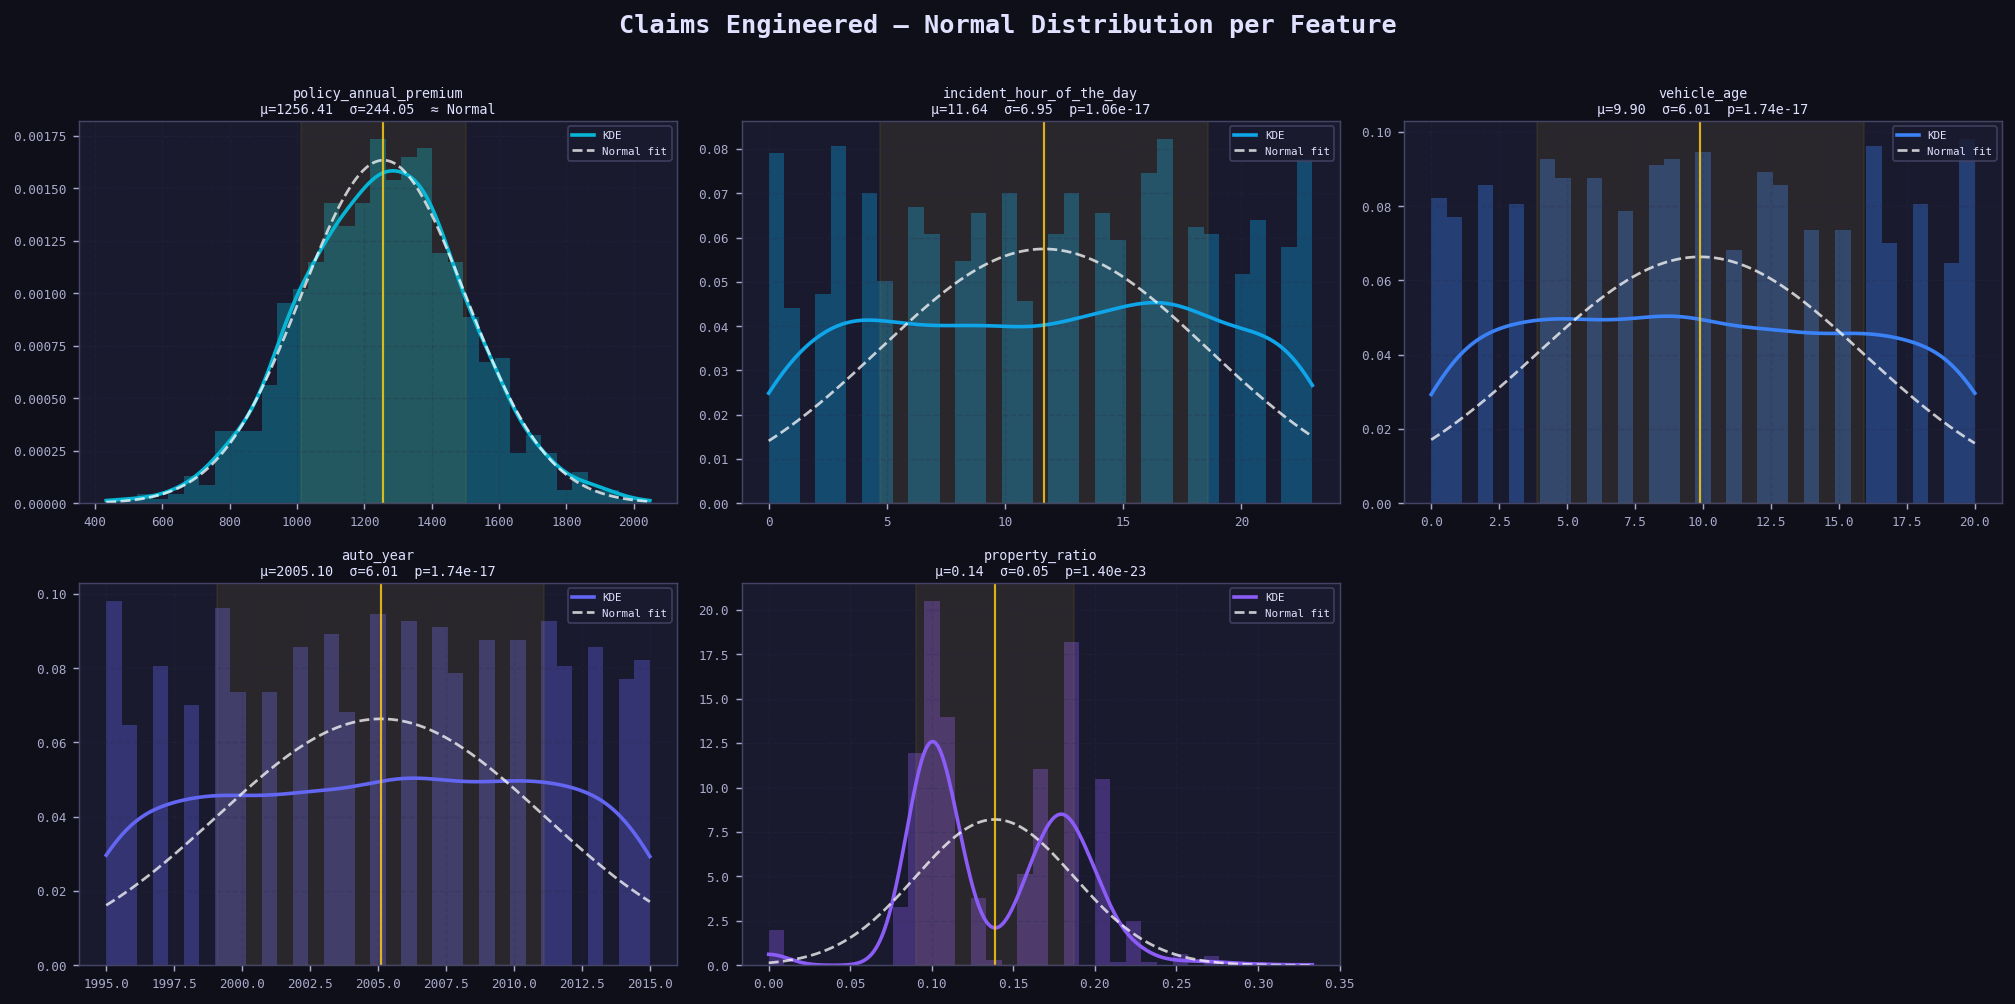

  → 5 distributions plotted



In [20]:
plot_normal_grid(
    claims_eng, ce_num,
    palette   = PALETTES["claims_eng"],
    title     = "Claims Engineered — Normal Distribution per Feature",
    cols_per_row = 3,
)

## 5 · Customer Engineered — Normal Distributions

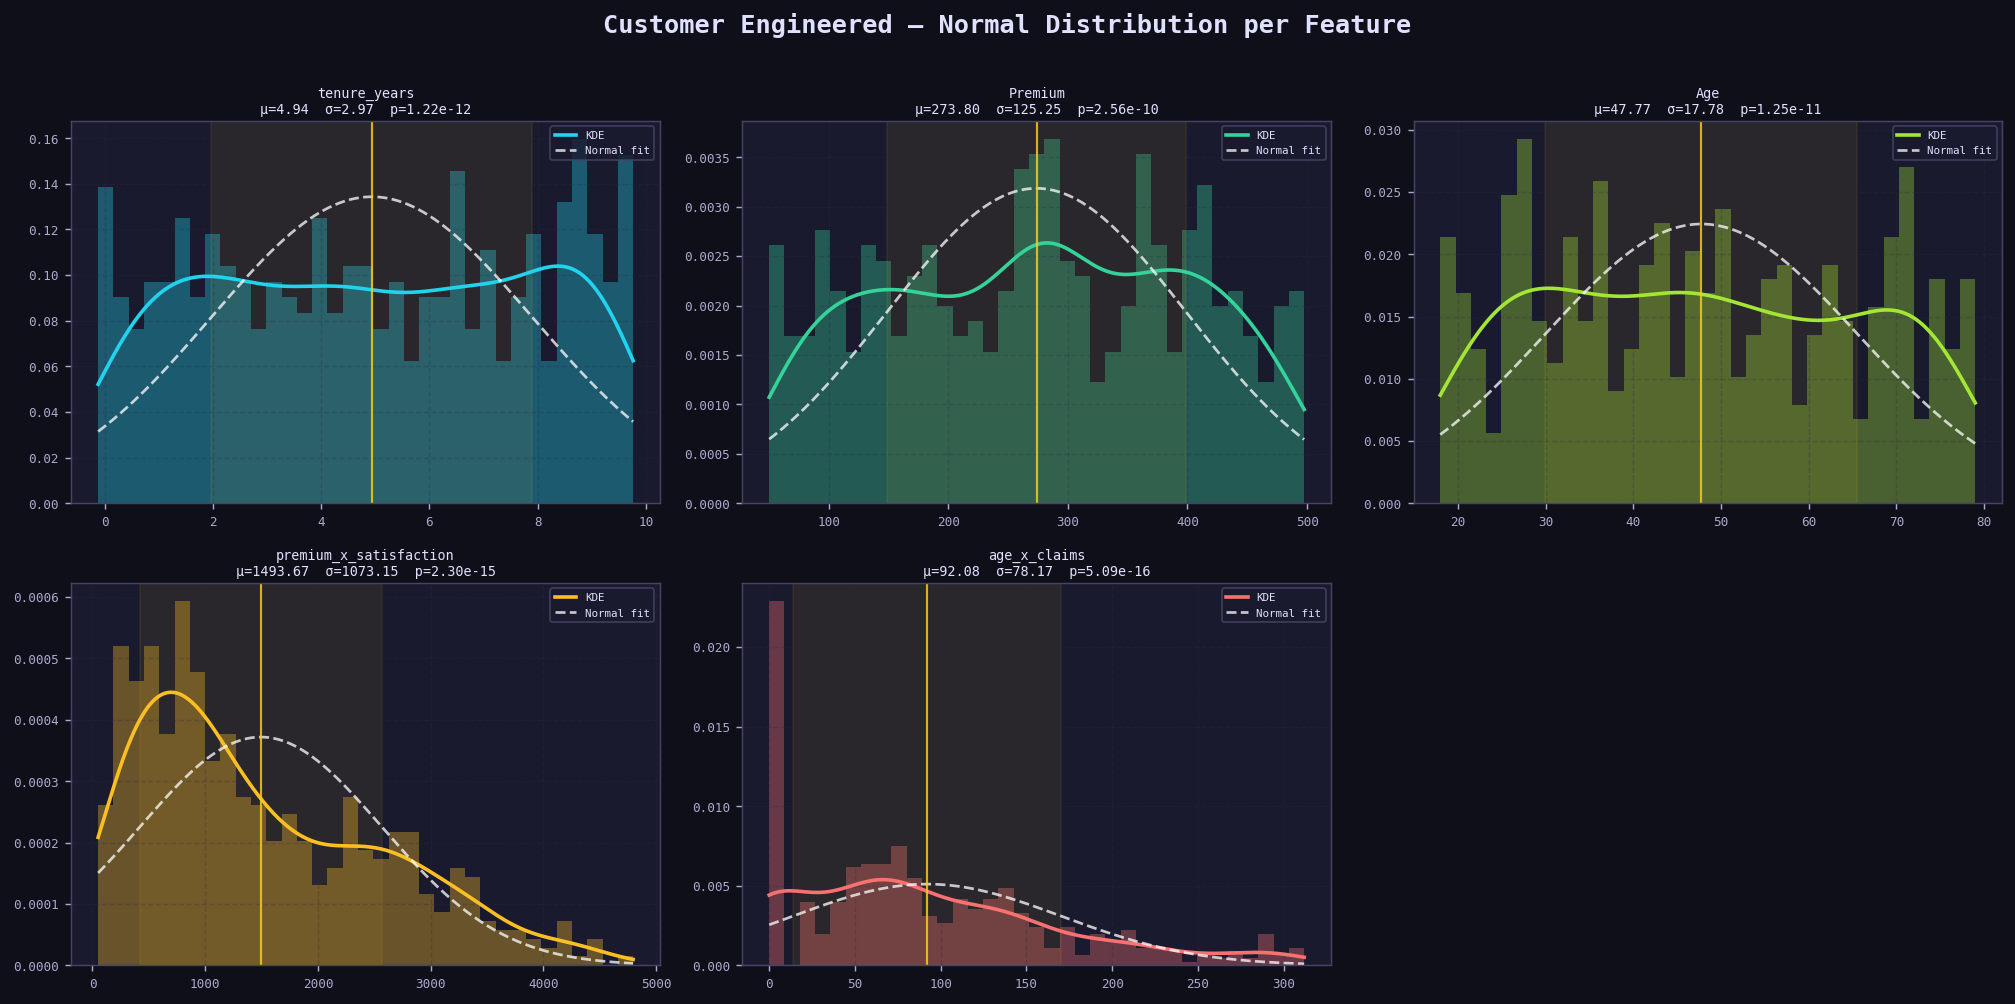

  → 5 distributions plotted



In [21]:
plot_normal_grid(
    customer, cu_num,
    palette   = PALETTES["customer"],
    title     = "Customer Engineered — Normal Distribution per Feature",
    cols_per_row = 3,
)

## 6 · Normality Summary (Shapiro-Wilk Test)

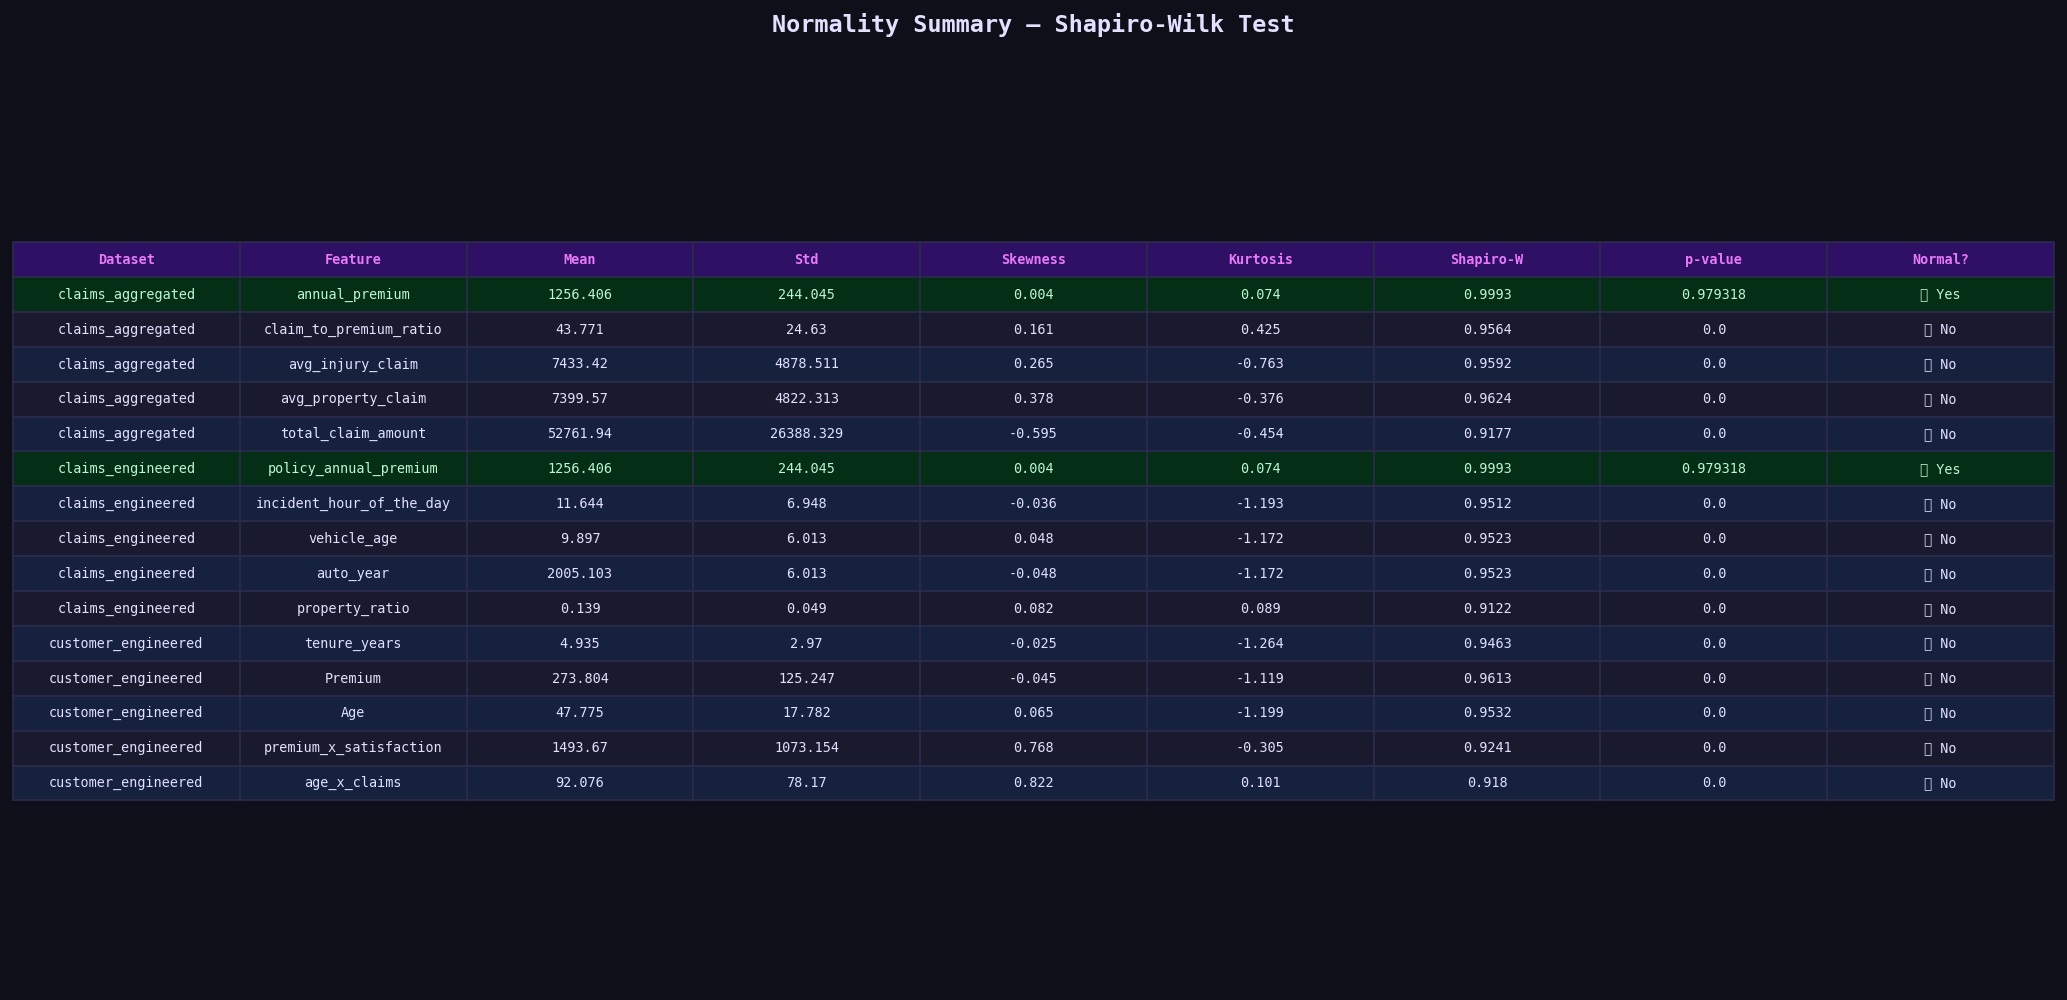

  Normally distributed features : 2 / 15
  Non-normal features           : 13 / 15


In [23]:
results = []
for label, df, cols in [
    ("claims_aggregated",  claims_agg, ca_num),
    ("claims_engineered",  claims_eng, ce_num),
    ("customer_engineered",customer,   cu_num),
]:
    for col in cols:
        data = df[col].dropna()
        mu, sigma = stats.norm.fit(data)
        sample = data if len(data) <= 5000 else data.sample(5000, random_state=42)
        stat, p  = stats.shapiro(sample)
        skew     = float(data.skew())
        kurt     = float(data.kurtosis())
        results.append({
            "Dataset": label, "Feature": col,
            "Mean": round(mu, 3), "Std": round(sigma, 3),
            "Skewness": round(skew, 3), "Kurtosis": round(kurt, 3),
            "Shapiro-W": round(stat, 4), "p-value": round(p, 6),
            "Normal?": "✅ Yes" if p > 0.05 else "❌ No",
        })

summary = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(16, len(summary) * 0.42 + 1.5))
ax.axis("off")
tbl = ax.table(
    cellText  = summary.values,
    colLabels = summary.columns,
    loc       = "center",
    cellLoc   = "center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(7.5)
tbl.scale(1, 1.35)

for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("#2a2a4a")
    if r == 0:
        cell.set_facecolor("#2e1065")
        cell.set_text_props(color="#e879f9", fontweight="bold")
    elif summary.iloc[r-1]["Normal?"] == "✅ Yes" if r > 0 else False:
        cell.set_facecolor("#052e16")
        cell.set_text_props(color="#bbf7d0")
    else:
        cell.set_facecolor("#1a1a2e" if r % 2 == 0 else "#16213e")
        cell.set_text_props(color="#e0e0ff")

fig.suptitle("Normality Summary — Shapiro-Wilk Test", fontsize=13,
             fontweight="bold", color="#e0e0ff", y=0.98)
plt.tight_layout()
plt.show()

normal_count = (summary["Normal?"] == "✅ Yes").sum()
print(f"{'='*50}")
print(f"  Normally distributed features : {normal_count} / {len(summary)}")
print(f"  Non-normal features           : {len(summary) - normal_count} / {len(summary)}")
print(f"{'='*50}")

## 7 · Q-Q Plots — Top Normal Features

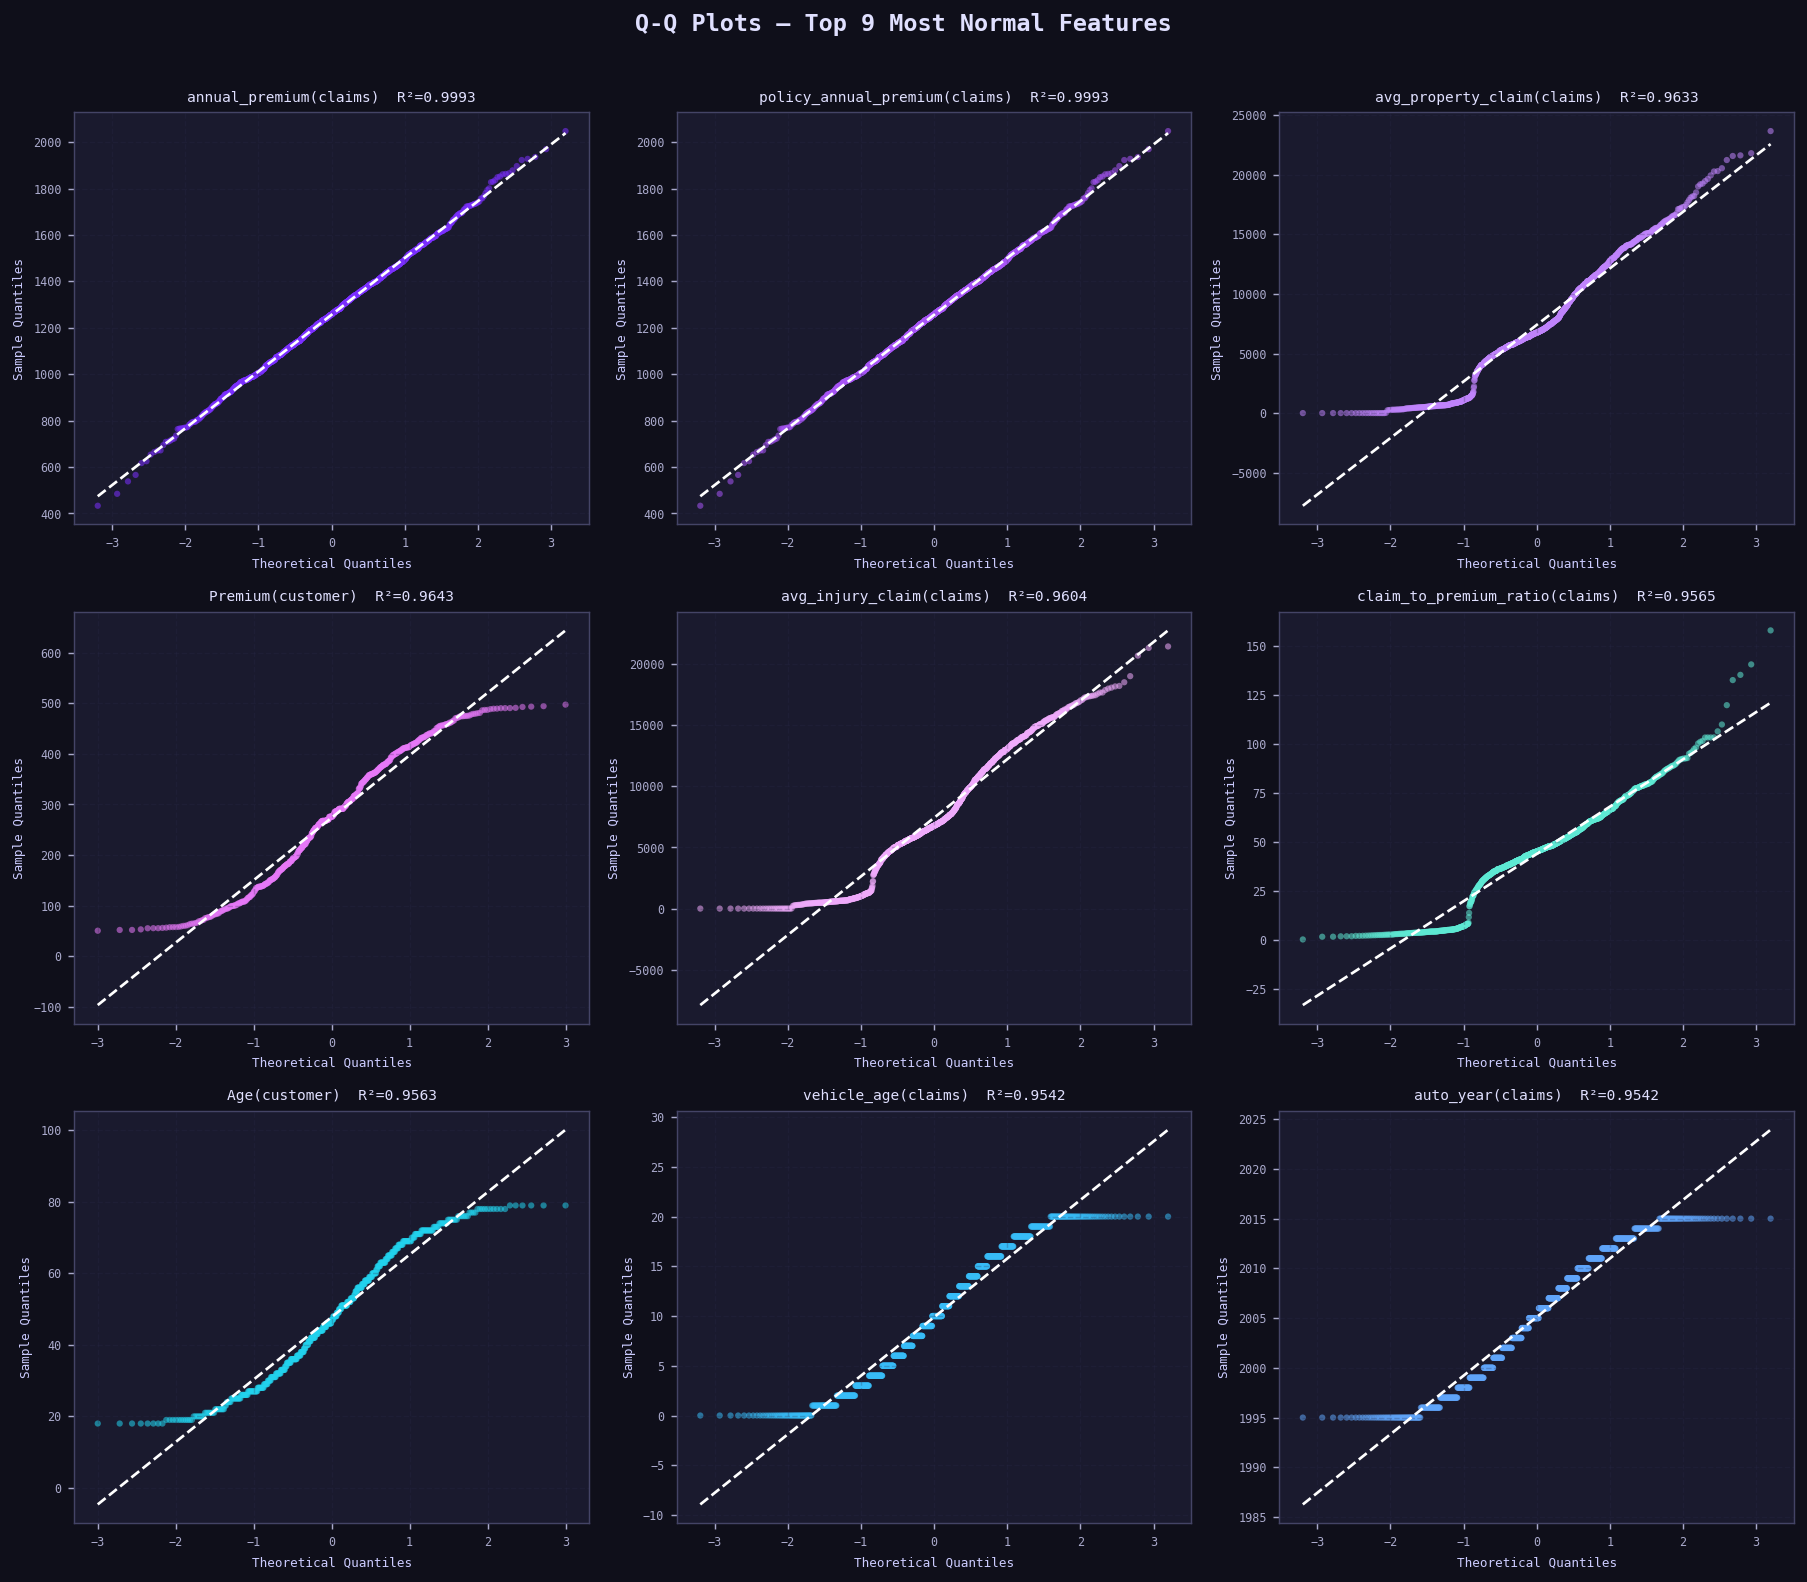

In [25]:
# Pick features most likely to be normal (highest Shapiro-W stat)
top_normal = (summary.sort_values("Shapiro-W", ascending=False)
                      .head(9).reset_index(drop=True))

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()
all_pal = PALETTES["claims_agg"] + PALETTES["customer"]

for i, row in top_normal.iterrows():
    ds_map = {
        "claims_aggregated" : claims_agg,
        "claims_engineered" : claims_eng,
        "customer_engineered": customer,
    }
    data = ds_map[row["Dataset"]][row["Feature"]].dropna()
    color = all_pal[i % len(all_pal)]
    ax = axes[i]

    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist="norm")
    ax.scatter(osm, osr, color=color, alpha=0.55, s=12, edgecolors="none")
    line_x = np.array([osm.min(), osm.max()])
    ax.plot(line_x, slope * line_x + intercept, color="#ffffff", lw=1.5, ls="--")

    ax.set_title(f"{row['Feature']}({row['Dataset'].split('_')[0]})  R²={r**2:.4f}",
                 fontsize=8, color="#e0e0ff")
    ax.set_xlabel("Theoretical Quantiles", fontsize=7)
    ax.set_ylabel("Sample Quantiles", fontsize=7)
    ax.tick_params(labelsize=6.5)
    ax.grid(True, alpha=0.25)

fig.suptitle("Q-Q Plots — Top 9 Most Normal Features",
             fontsize=13, fontweight="bold", color="#e0e0ff", y=1.01)
plt.tight_layout()
plt.show()

## 8 · Export — Save Each Plot as PNG

In [26]:
import os

# ── Output folder ─────────────────────────────────────────────────
EXPORT_DIR = "distribution_plots"
os.makedirs(EXPORT_DIR, exist_ok=True)

ACCENT_COLORS = [
    "#7b2fff","#a855f7","#c084fc","#22d3ee","#38bdf8",
    "#34d399","#4ade80","#facc15","#f97316","#f472b6",
    "#fb7185","#60a5fa","#818cf8","#e879f9","#5eead4",
]

DATASETS = [
    ("Claims_Aggregated",  claims_agg, ca_num),
    ("Claims_Engineered",  claims_eng, ce_num),
    ("Customer_Engineered",customer,   cu_num),
]

saved = []
idx   = 0

for ds_name, df, cols in DATASETS:
    for col in cols:
        data = df[col].dropna()
        if data.std() < 1e-10 or data.nunique() <= 2:
            print(f"  ⚠️  Skipped {col} (low variance)")
            continue

        color = ACCENT_COLORS[idx % len(ACCENT_COLORS)]
        fig, ax = plt.subplots(figsize=(7, 4.5))
        fig.patch.set_facecolor("#0f0f1a")

        # Histogram
        ax.hist(data, bins=35, density=True, color=color, alpha=0.35, edgecolor="none")

        xs = np.linspace(data.min(), data.max(), 300)

        # KDE
        try:
            kde = stats.gaussian_kde(data)
            ax.plot(xs, kde(xs), color=color, lw=2.5, label="KDE")
        except Exception:
            pass

        # Normal fit
        mu, sigma = stats.norm.fit(data)
        if sigma > 0:
            ax.plot(xs, stats.norm.pdf(xs, mu, sigma),
                    color="#ffffff", lw=1.8, ls="--", alpha=0.8, label="Normal fit")

        # Mean & ±1σ
        ax.axvline(mu, color="#facc15", lw=1.4, alpha=0.9, label=f"μ = {mu:.2f}")
        ax.axvspan(mu - sigma, mu + sigma, alpha=0.08, color="#facc15", label=f"±1σ = {sigma:.2f}")

        # Shapiro-Wilk
        sample = data if len(data) <= 5000 else data.sample(5000, random_state=42)
        try:
            _, p = stats.shapiro(sample)
            normal_tag = "≈ Normal" if p > 0.05 else f"Non-Normal  p={p:.2e}"
        except Exception:
            normal_tag = "n/a"

        ax.set_title(
            f"{ds_name.replace('_', ' ')}  ·  {col}\n"
            f"Skewness={data.skew():.3f}   {normal_tag}",
            fontsize=10, pad=10, color="#e0e0ff", fontweight="bold"
        )
        ax.set_xlabel(col, fontsize=9)
        ax.set_ylabel("Density", fontsize=9)
        ax.legend(fontsize=7.5, loc="upper right",
                  facecolor="#1a1a2e", edgecolor="#444466")
        ax.grid(True, alpha=0.25)
        plt.tight_layout()

        fname = f"{ds_name}_{col}.png"
        fpath = os.path.join(EXPORT_DIR, fname)
        plt.savefig(fpath, dpi=150, bbox_inches="tight", facecolor="#0f0f1a")
        plt.close()
        saved.append(fname)
        print(f"  ✅ {fname}")
        idx += 1

print(f"\n🎉 {len(saved)} images saved to '{EXPORT_DIR}/'")

  ✅ Claims_Aggregated_annual_premium.png
  ✅ Claims_Aggregated_claim_to_premium_ratio.png
  ✅ Claims_Aggregated_avg_injury_claim.png
  ✅ Claims_Aggregated_avg_property_claim.png
  ✅ Claims_Aggregated_total_claim_amount.png
  ✅ Claims_Engineered_policy_annual_premium.png
  ✅ Claims_Engineered_incident_hour_of_the_day.png
  ✅ Claims_Engineered_vehicle_age.png
  ✅ Claims_Engineered_auto_year.png
  ✅ Claims_Engineered_property_ratio.png
  ✅ Customer_Engineered_tenure_years.png
  ✅ Customer_Engineered_Premium.png
  ✅ Customer_Engineered_Age.png
  ✅ Customer_Engineered_premium_x_satisfaction.png
  ✅ Customer_Engineered_age_x_claims.png

🎉 15 images saved to 'distribution_plots/'
